In [14]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
import pandas as pd
from sklearn.model_selection import train_test_split

In [15]:
insurance_data = pd.read_csv("insurance.csv")

x = insurance_data.drop(columns=["charges"])
y = insurance_data["charges"]

x = pd.get_dummies(x, columns=["region"], drop_first=True, dtype=int)

x["sex"] = x["sex"].map({"female": 1, "male": 0})
x["smoker"] = x["smoker"].map({"yes": 1, "no": 0})

x["age_smoker"] = x["age"] * x["smoker"]
x["bmi_smoker"] = x["age"] * x["smoker"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

MSE for alpha=0.001: 33706954.097168684
MSE for alpha=0.1: 33708028.710970335
MSE for alpha=1: 33718022.02407517
MSE for alpha=2: 33730907.210739136
MSE for alpha=5: 33770683.91292829
MSE for alpha=10: 33838341.14755934
MSE for alpha=20: 33981011.16207822
MSE for alpha=30: 34132116.75700414
MSE for alpha=40: 34291664.136452205
MSE for alpha=50: 34463083.07001966
MSE for alpha=100: 35228851.164516054


<Axes: >

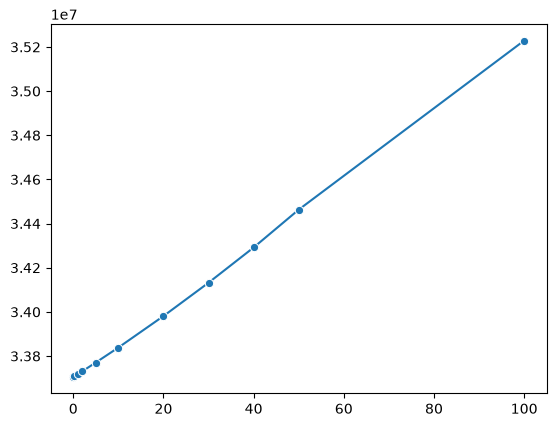

In [16]:
import seaborn as sns

alphas = [0.001, 0.1, 1, 2, 5, 10, 20, 30, 40, 50, 100]
meses = []

for a in alphas:
    lasso_model = Lasso(alpha=a)
    
    lasso_model.fit(x_train, y_train)
    
    y_pred = lasso_model.predict(x_test)
    
    mse = mean_squared_error(y_test, y_pred)
    
    print(f"MSE for alpha={a}:", mse)
    meses.append(mse)

sns.lineplot(x=alphas, y=meses,marker="o")

In [20]:
from sklearn.linear_model import LassoCV
a = [0.001,0.1, 1, 2, 5, 10, 20, 30, 40, 50, 100]

lasso_cv_model = LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000,
    random_state=42
)

lasso_cv_model.fit(x_train, y_train)

print("best alpha", lasso_cv_model.alpha_)

y_pred = lasso_cv_model.predict(x_test)

best alpha 30.0
